In [10]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)

import numpy as np
import pandas as pd
from os import listdir
from os.path import isfile, join
from mhcnames import normalize_allele_name
import mhcnames
import mhcgnomes


# 1. Read data

In [11]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
DATA_PATH = f'{DATA_PATH_BASE}/core_identification_paper/' #Work laptop

# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu

In [12]:
onlyfiles = [f for f in listdir(DATA_PATH) if isfile(join(DATA_PATH, f))]
ALLELES = []
NOT_NORMALIZED = []
per_allele_train_df = dict()
for file_name in onlyfiles:
    allele_name = file_name.split("#", 1)[1].split('.')[0]
    NOT_NORMALIZED.append(allele_name)
    allele_name = mhcgnomes.parse(allele_name).to_string()
    per_allele_train_df[allele_name] =  pd.read_csv(DATA_PATH + file_name,sep=";")
    ALLELES.append(allele_name)
ALLELES

['HLA-A*02:01',
 'HLA-A*03:01',
 'HLA-A*01:01',
 'HLA-A*24:02',
 'HLA-B*27:05',
 'HLA-B*07:02',
 'HLA-B*57:01',
 'HLA-B*15:02',
 'HLA-C*12:02',
 'HLA-DRB1*01:01',
 'HLA-DRB1*04:01',
 'HLA-DRB1*07:01',
 'HLA-DRB1*04:04',
 'HLA-DPA1*02:02/DPB1*05:01',
 'HLA-DQA1*05:01/DQB1*02:01']

In [14]:
mhcnames.compact_allele_name('HLA-DPA1*01:03-DPB1*04:01')

'DPA10103-DPB10401'

In [16]:
mhcgnomes.parse('HLA-DPA1*01:03-DPB1*04:01').compact_string(include_species=True).replace("*", "_")

'HLA-DPA1_0103-DPB1_0401'

In [18]:
mhcgnomes.parse('HLA-DRB1*04:01').compact_string(include_species=True).replace("*", "_")


'HLA-DRB1_0401'

In [19]:
mhcgnomes.parse('HLA-DRB1_0401')

Allele(gene=Gene(species=Species(name='Homo sapiens', mhc_prefix='HLA'), name='DRB1', mutations=()), allele_fields=('04', '01'), annotations=(), mutations=())

# 2. Make per length split

In [7]:
from sklearn.model_selection import KFold
MIN_LENGTH = 8
MAX_LENGTH = 30

#leave only binders
def getBindersPeptidesOnly(df):
    result_peptides = df[df['binder'] == 1]['peptide'].values
    return result_peptides
def getNonBindersPeptidesOnly(df):
    result_peptides = df[df['binder'] == 0]['peptide'].values
    return result_peptides

def make_per_length_dict(df, binder_flag):
    lengths = set(df['length'])
    lengths = set([length for length in lengths if length >= MIN_LENGTH and length <= MAX_LENGTH])
    per_length_dict = dict()
    for length in lengths:
        result_peptides = df[(df['binder'] == binder_flag) & (df['length'] == length)]['peptide'].values
        per_length_dict[length] = result_peptides
    return per_length_dict

kf = KFold(n_splits=5, shuffle=True)
def make_per_length_per_KFold_dict(per_length_dict):

    per_length_per_kfold_peptides_train = dict()
    per_length_per_kfold_peptides_test = dict()

    print("Length \t Train/Test for splits", end="")
    for target_length in per_length_dict.keys():
        print(f"\n{target_length}:", end="\t")
        peptides_array = per_length_dict[target_length]
        per_length_per_kfold_peptides_train[target_length] = dict()
        per_length_per_kfold_peptides_test[target_length] = dict()
        if len(peptides_array) > kf.n_splits:
            i = 0
            for train_indexes_b, test_indexes_b in kf.split(peptides_array):
                print("{}/{}\t".format(len(train_indexes_b), len(test_indexes_b)), end="")
                current_train = peptides_array[train_indexes_b]
                current_test = peptides_array[test_indexes_b]
                per_length_per_kfold_peptides_train[target_length][i] = current_train
                per_length_per_kfold_peptides_test[target_length][i] = current_test
                i = i + 1
        else:

            print(f"Not enough peptides of length {target_length}", end="")
    print()
    return per_length_per_kfold_peptides_train , per_length_per_kfold_peptides_test





def addAuxColumns(per_allele_df):
    for allele_name, df in per_allele_df.items():
        df['length'] = df['peptide'].str.len()

per_allele_binders_train = dict()
per_allele_non_binders_train = dict()
per_allele_per_length_binders_train = dict()
per_allele_per_length_non_binders_train = dict()
per_allele_per_length_per_kfold_binders_train = dict()
per_allele_per_length_per_kfold_binders_test = dict()
per_allele_per_length_per_kfold_non_binders_train = dict()
per_allele_per_length_per_kfold_non_binders_test = dict()


for allele_name in ALLELES:
    print(f"Allele {allele_name}")
    df_train = per_allele_train_df[allele_name]
    df_train = df_train.sample(frac=1).reset_index(drop=True)
    per_allele_binders_train[allele_name] = getBindersPeptidesOnly(df_train)
    per_allele_non_binders_train[allele_name] = getNonBindersPeptidesOnly(df_train)
    per_allele_per_length_binders_train[allele_name] = make_per_length_dict(df_train, binder_flag=1)
    per_allele_per_length_non_binders_train[allele_name] = make_per_length_dict(df_train, binder_flag=0)
    print(f"Binders")
    per_allele_per_length_per_kfold_binders_train[allele_name],  per_allele_per_length_per_kfold_binders_test[allele_name] = make_per_length_per_KFold_dict(per_allele_per_length_binders_train[allele_name])
    print(f"Non-binders")
    per_allele_per_length_per_kfold_non_binders_train[allele_name],  per_allele_per_length_per_kfold_non_binders_test[allele_name] = make_per_length_per_KFold_dict(per_allele_per_length_non_binders_train[allele_name])


Allele HLA-A*02:01
Binders
Length 	 Train/Test for splits
8:	2925/732	2925/732	2926/731	2926/731	2926/731	
9:	32152/8039	32153/8038	32153/8038	32153/8038	32153/8038	
10:	9005/2252	9005/2252	9006/2251	9006/2251	9006/2251	
11:	4652/1163	4652/1163	4652/1163	4652/1163	4652/1163	
12:	1550/388	1550/388	1550/388	1551/387	1551/387	
13:	841/211	841/211	842/210	842/210	842/210	
14:	622/156	622/156	622/156	623/155	623/155	
15:	606/152	606/152	606/152	607/151	607/151	
16:	426/107	426/107	426/107	427/106	427/106	
17:	269/68	269/68	270/67	270/67	270/67	
18:	179/45	179/45	179/45	179/45	180/44	
19:	116/30	117/29	117/29	117/29	117/29	
20:	107/27	107/27	107/27	107/27	108/26	
21:	58/15	58/15	58/15	59/14	59/14	
22:	35/9	35/9	35/9	35/9	36/8	
23:	28/8	29/7	29/7	29/7	29/7	
24:	20/6	21/5	21/5	21/5	21/5	
25:	16/5	17/4	17/4	17/4	17/4	
26:	6/2	6/2	6/2	7/1	7/1	
27:	13/4	13/4	14/3	14/3	14/3	
28:	8/2	8/2	8/2	8/2	8/2	
29:	5/2	5/2	6/1	6/1	6/1	
30:	5/2	5/2	6/1	6/1	6/1	
Non-binders
Length 	 Train/Test for splits
8:	103

In [8]:
ALLELES

['HLA-A*02:01',
 'HLA-A*03:01',
 'HLA-A*01:01',
 'HLA-A*24:02',
 'HLA-B*27:05',
 'HLA-B*07:02',
 'HLA-B*57:01',
 'HLA-B*15:02',
 'HLA-C*12:02',
 'HLA-DRB1*01:01',
 'HLA-DRB1*04:01',
 'HLA-DRB1*07:01',
 'HLA-DRB1*04:04',
 'HLA-DPA1*02:02/DPB1*05:01',
 'HLA-DQA1*05:01/DQB1*02:01']

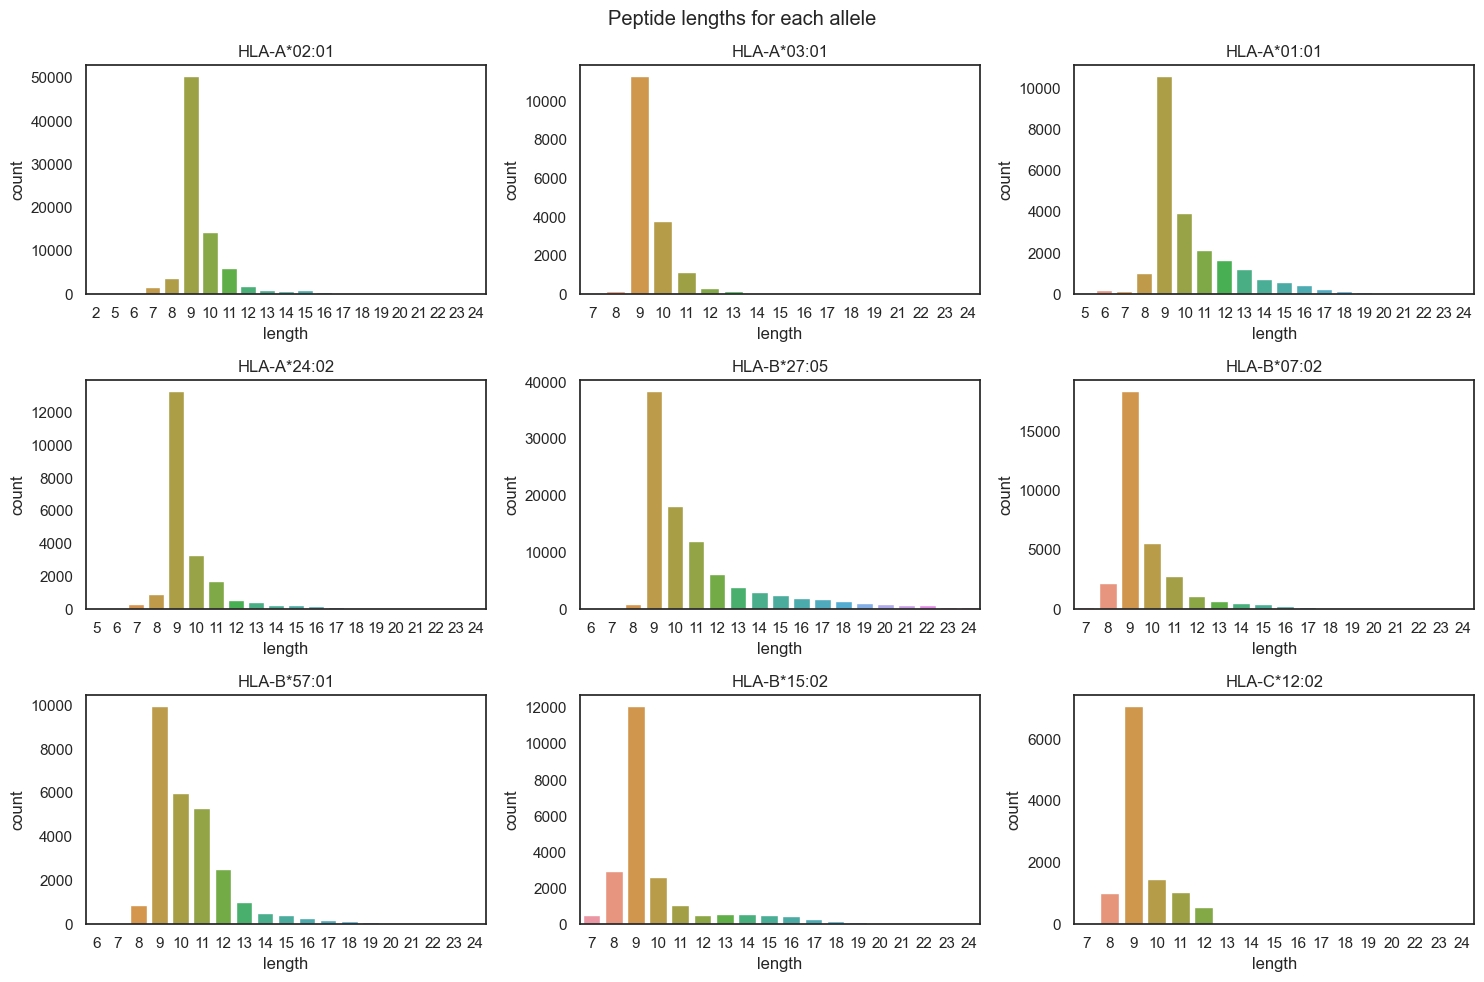

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt
class1 = ['HLA-A*02:01',
 'HLA-A*03:01',
 'HLA-A*01:01',
 'HLA-A*24:02',
 'HLA-B*27:05',
 'HLA-B*07:02',
 'HLA-B*57:01',
 'HLA-B*15:02',
 'HLA-C*12:02',]

class2 = ['HLA-DRB1*01:01',
 'HLA-DRB1*04:01',
 'HLA-DRB1*07:01',
 'HLA-DRB1*04:04',
          ]

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 10))


for cur_ax, allele_name in zip(axes.flatten(), class1):
    df = per_allele_train_df[allele_name]
    ax = sns.countplot(df[df.length< 25], x='length', ax=cur_ax)
    ax.set(title=f'{allele_name}')
    ax.figure.suptitle(f'Peptide lengths for each allele')
plt.tight_layout()
# ax.set(yscale="log")

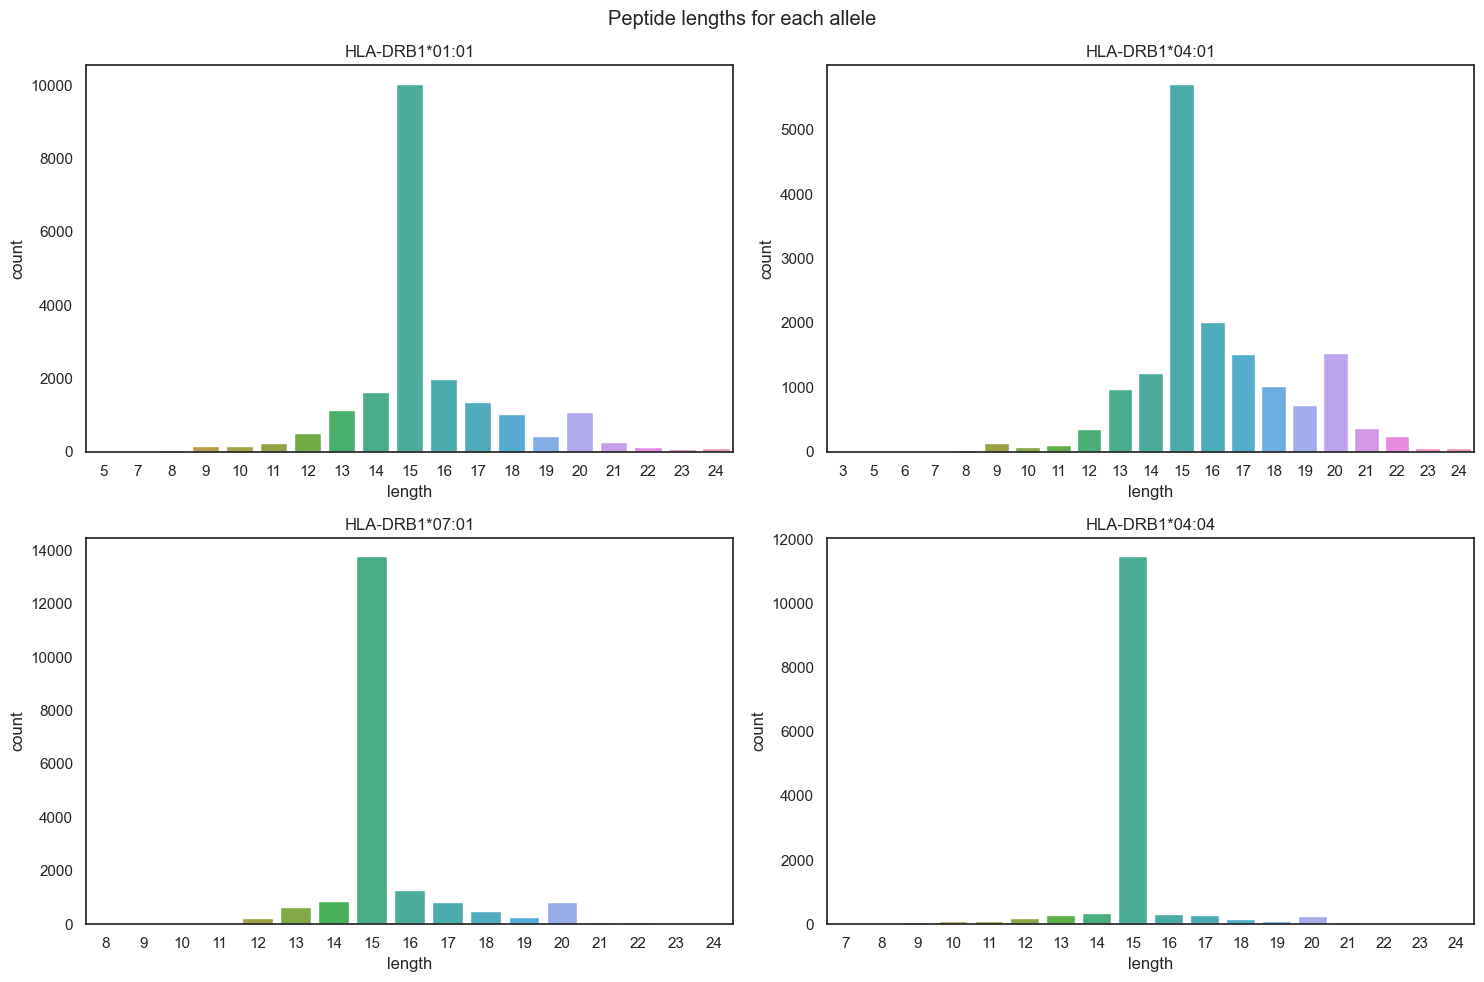

In [55]:
class2 = ['HLA-DRB1*01:01',
 'HLA-DRB1*04:01',
 'HLA-DRB1*07:01',
 'HLA-DRB1*04:04']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))


for cur_ax, allele_name in zip(axes.flatten(), class2):
    df = per_allele_train_df[allele_name]
    ax = sns.countplot(df[df.length< 25], x='length', ax=cur_ax)
    ax.set(title=f'{allele_name}')
    ax.figure.suptitle(f'Peptide lengths for each allele')
plt.tight_layout()

In [56]:
import logomaker
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

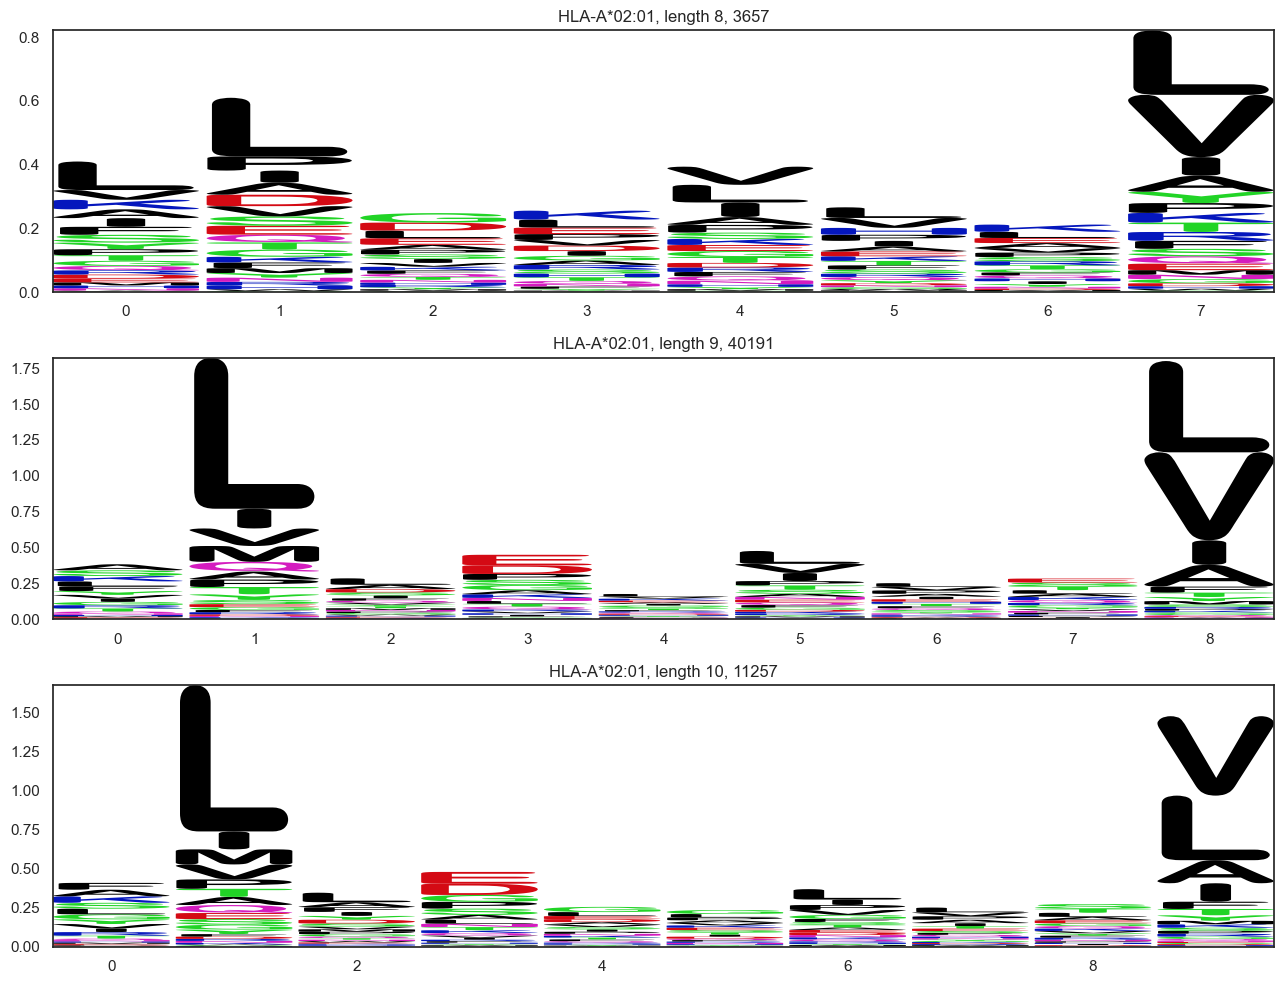

In [57]:
target_allele_name = class1[0]
TARGET_LENGTHS = [8, 9 ,10]

fig, axes = plt.subplots(nrows=len(TARGET_LENGTHS), ncols=1, figsize=(13, 10))
for target_length, cur_ax in zip(TARGET_LENGTHS, axes.flatten()):
    make_logo_for_data(per_allele_per_length_binders_train[target_allele_name][target_length], f"{target_allele_name}, length {target_length}", ax=cur_ax)

plt.tight_layout()

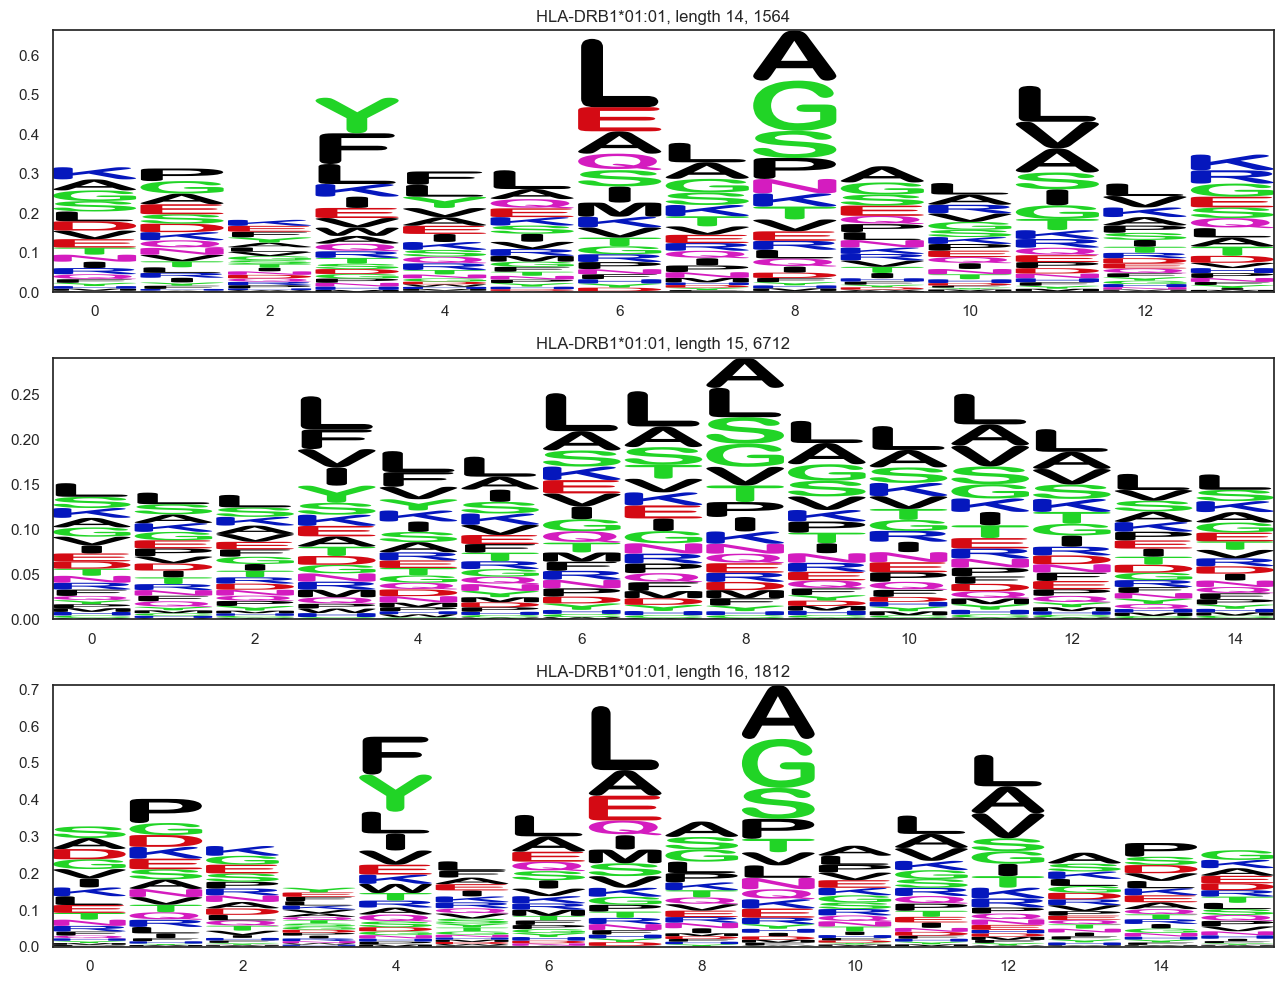

In [58]:
target_allele_name = class2[0]
TARGET_LENGTHS = [14, 15 ,16]

fig, axes = plt.subplots(nrows=len(TARGET_LENGTHS), ncols=1, figsize=(13, 10))
for target_length, cur_ax in zip(TARGET_LENGTHS, axes.flatten()):
    make_logo_for_data(per_allele_per_length_binders_train[target_allele_name][target_length], f"{target_allele_name}, length {target_length}", ax=cur_ax)

plt.tight_layout()

# 3. Save per_length_per_split to files

In [9]:
import os
from collections import defaultdict

TARGET_PATH_TO_FILES = DATA_PATH  + '/per_length_per_kfold_split/'
if not os.path.exists(TARGET_PATH_TO_FILES):
    os.makedirs(TARGET_PATH_TO_FILES)

def save_data(per_allele_per_length_per_kfold_data, data_type=None, dataset_type=None):
    assert data_type in ["binders", "nonbinders"]
    assert dataset_type in ["train", "test"]

    per_allele_dfs = defaultdict(list)
    for allele_name in per_allele_per_length_per_kfold_data.keys():
        for length, per_k_fold_dict in per_allele_per_length_per_kfold_data[allele_name].items():
                for split_num, peptides in per_k_fold_dict.items():
                    df = pd.DataFrame({"peptide":peptides, "length":length, "split": split_num})
                    per_allele_dfs[allele_name].append(df)
        total_df= pd.concat(per_allele_dfs[allele_name])
        target_allele_name = mhcgnomes.parse(allele_name).compact_string(include_species=True).replace("*", "_")
        total_df.to_csv(f'{TARGET_PATH_TO_FILES}{target_allele_name}#{data_type}#{dataset_type}.csv',sep=";", index=False)


save_data(per_allele_per_length_per_kfold_binders_train, "binders", "train")
# save_data(per_allele_per_length_per_kfold_non_binders_train, "nonbinders", "train")
save_data(per_allele_per_length_per_kfold_binders_test, "binders", "test")
# save_data(per_allele_per_length_per_kfold_non_binders_test, "nonbinders", "test")

In [60]:
 mhcnames.compact_allele_name(allele_name)

'DRB10404'

In [61]:
allele_name

'HLA-DRB1*04:04'

In [64]:
mhcgnomes.parse(mhcgnomes.parse(allele_name).compact_string(include_species=True).replace("*", "-"))

Allele(gene=Gene(species=Species(name='Homo sapiens', mhc_prefix='HLA'), name='DRB1', mutations=()), allele_fields=('04', '04'), annotations=(), mutations=())